# ThemeSync — Results Analysis

Consultation-ready summary of the real, measured results collected so far
against the manuscript's own 4-phase Research Procedure (Chapter 3, pp. 50-58).
Every number here is loaded from an actual artifact in the repo — nothing is
hand-typed or estimated — so re-running this notebook after a new pipeline run
or YOLO retrain refreshes it automatically.

**Sources used:**
- `runs/yolo/themesync_layout_yolo/results.csv` — Stage 0b YOLOv8, CGL-Dataset pretrain (`themesync_yolo_v1.pt`)
- `runs/yolo/themesync_master_layout_finetune/results.csv` — Stage 0b YOLOv8, 65-image real-poster fine-tune (`themesync_yolo_v2.pt`)
- `runs/yolo/themesync_master_layout_finetune_v3/results.csv` — Stage 0b YOLOv8, 124-image real-poster fine-tune, continued from v2 (`themesync_yolo_v3.pt`)
- `results/experiment_log.json` — Phase 3 multi-trial GNN-guided vs. baseline heuristic fitness, both domains
- `results/evaluation_results.json` — Phase 3 fixed-comparison run (the one `tests/test_certificate_pipeline.py` asserts against)
- Phase 4 (MOS / expert validation): **no real data yet** — section kept as a placeholder, see bottom

Full narrative/evidence behind every number: `notes/gnn_fixes_and_methodology_notes.md`
sections 3.6-3.7 (YOLO) and the Phase 3 test suites.


In [1]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "results").exists():
    ROOT = ROOT.parent  # allow running from notebooks/ or repo root

# Validated categorical palette (dataviz skill reference palette -- fixed order,
# never cycled; slots 1/2 clear the adjacent-pair CVD/contrast gates together).
SERIES_1 = "#2a78d6"   # blue   -- v1 / GNN-guided / "before"
SERIES_2 = "#eb6834"   # orange -- v2 / Baseline / "after"
SERIES_3 = "#1baf7a"   # aqua   -- third series when needed
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
GRID = "#e3e2dd"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "text.color": TEXT_PRIMARY,
    "axes.labelcolor": TEXT_SECONDARY,
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "font.size": 10,
})


## Phase 1 -- YOLOv8 Layout Parser: CGL Pretrain -> v2 (65 img) -> v3 (124 img)

`themesync_yolo_v1.pt` was trained on the public CGL-Dataset. `themesync_yolo_v2.pt`
fine-tuned it on 65 real, hand-annotated CSPC SSC poster images. `themesync_yolo_v3.pt`
continues from v2 on an expanded 124-image batch (the original 65 plus 59 more).
v1's validation set (CGL's own held-out split) isn't comparable to v2/v3's (this
project's own real-poster held-out split), so v1 gets its own chart; v2 and v3
share a held-out methodology and are directly comparable, so they're overlaid.


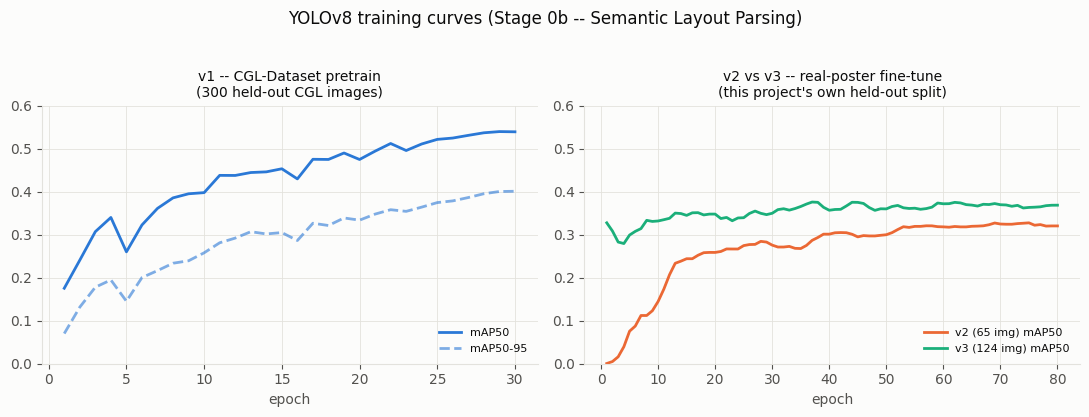

In [2]:
v1 = pd.read_csv(ROOT / "runs/yolo/themesync_layout_yolo/results.csv")
v2 = pd.read_csv(ROOT / "runs/yolo/themesync_master_layout_finetune/results.csv")
v3 = pd.read_csv(ROOT / "runs/yolo/themesync_master_layout_finetune_v3/results.csv")
v1.columns = [c.strip() for c in v1.columns]
v2.columns = [c.strip() for c in v2.columns]
v3.columns = [c.strip() for c in v3.columns]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(v1["epoch"], v1["metrics/mAP50(B)"], color=SERIES_1, linewidth=2, label="mAP50")
axes[0].plot(v1["epoch"], v1["metrics/mAP50-95(B)"], color=SERIES_1, linewidth=2,
             linestyle="--", alpha=0.6, label="mAP50-95")
axes[0].set_title("v1 -- CGL-Dataset pretrain\n(300 held-out CGL images)", fontsize=10)

for df, label, color in [(v2, "v2 (65 img)", SERIES_2), (v3, "v3 (124 img)", SERIES_3)]:
    axes[1].plot(df["epoch"], df["metrics/mAP50(B)"], color=color, linewidth=2, label=f"{label} mAP50")
axes[1].set_title("v2 vs v3 -- real-poster fine-tune\n(this project's own held-out split)", fontsize=10)

for ax in axes:
    ax.set_xlabel("epoch")
    ax.set_ylim(0, 0.6)
    ax.legend(frameon=False, fontsize=8, loc="lower right")

fig.suptitle("YOLOv8 training curves (Stage 0b -- Semantic Layout Parsing)", y=1.03)
fig.tight_layout()
plt.show()


In [3]:
summary = pd.DataFrame([
    {
        "model": "v1 (CGL pretrain)",
        "val_set": "300 CGL held-out images / 1448 instances",
        "precision": v1["metrics/precision(B)"].iloc[-1],
        "recall": v1["metrics/recall(B)"].iloc[-1],
        "mAP50": v1["metrics/mAP50(B)"].iloc[-1],
        "mAP50-95": v1["metrics/mAP50-95(B)"].iloc[-1],
    },
    {
        "model": "v2 (65-image real-poster fine-tune)",
        "val_set": "15 held-out real posters",
        "precision": v2["metrics/precision(B)"].iloc[-1],
        "recall": v2["metrics/recall(B)"].iloc[-1],
        "mAP50": v2["metrics/mAP50(B)"].iloc[-1],
        "mAP50-95": v2["metrics/mAP50-95(B)"].iloc[-1],
    },
    {
        "model": "v3 (124-image real-poster fine-tune)",
        "val_set": "25 held-out real posters",
        "precision": v3["metrics/precision(B)"].iloc[-1],
        "recall": v3["metrics/recall(B)"].iloc[-1],
        "mAP50": v3["metrics/mAP50(B)"].iloc[-1],
        "mAP50-95": v3["metrics/mAP50-95(B)"].iloc[-1],
    },
]).set_index("model")
summary.round(3)


,val_set,precision,recall,mAP50,mAP50-95
model,,,,,
v1 (CGL pretrain),300 CGL held-out images / 1448 instances,0.580,0.478,0.539,0.401
v2 (65-image real-poster fine-tune),15 held-out real posters,0.627,0.304,0.320,0.183
v3 (124-image real-poster fine-tune),25 held-out real posters,0.459,0.349,0.368,0.212


### A real data-quality catch, before v3 existed

Checking the newly-uploaded 124-image export before training on it found two
real problems, confirmed with an actual test run rather than assumed: (1)
~23% of the images were being silently dropped during training because their
label files mixed plain bounding-box rows with polygon rows -- Ultralytics
discards the whole file rather than partially using it; (2) the class index
order had shifted between exports (alphabetized in the new one), which would
have silently scrambled what v2's checkpoint had already learned if fine-tuned
on as-is. Both fixed (polygons converted to their enclosing boxes, indices
remapped) and re-verified (0 corrupt files) before the retrain below ran. Full
detail: `notes/gnn_fixes_and_methodology_notes.md` Section 3.12.


### Per-class breakdown: v2 vs v3

Not in `results.csv` (Ultralytics only logs aggregate metrics there) -- pulled
from the console output captured in `notes/gnn_fixes_and_methodology_notes.md`
Sections 3.7 (v2) and 3.12 (v3). **`underlay` is still weak** (44 validation
instances now, up from 17 -- better, not yet enough to learn well);
**`embellishment` stayed flat** despite the batch nearly doubling (consistent
with the group's decision not to prioritize hunting for these); `logo` and
`text` -- the two structurally important classes -- both improved meaningfully.


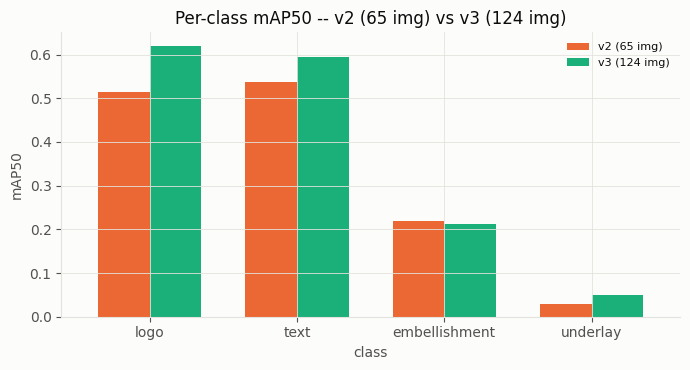

,v2_mAP50,v3_mAP50
class,,
logo,0.5150,0.6200
text,0.5380,0.5950
embellishment,0.2180,0.2130
underlay,0.0288,0.0499


In [4]:
per_class = pd.DataFrame([
    {"class": "logo",          "v2_mAP50": 0.515,  "v3_mAP50": 0.620},
    {"class": "text",          "v2_mAP50": 0.538,  "v3_mAP50": 0.595},
    {"class": "embellishment", "v2_mAP50": 0.218,  "v3_mAP50": 0.213},
    {"class": "underlay",      "v2_mAP50": 0.0288, "v3_mAP50": 0.0499},
]).set_index("class")

ax = per_class.plot(kind="bar", color=[SERIES_2, SERIES_3], figsize=(7, 3.8), width=0.7)
ax.set_ylabel("mAP50")
ax.set_title("Per-class mAP50 -- v2 (65 img) vs v3 (124 img)")
ax.set_xticklabels(per_class.index, rotation=0)
ax.legend(["v2 (65 img)", "v3 (124 img)"], frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

per_class


### Real-domain generalization check (v1 -> v2, same 3 unseen posters)

Top detection confidence on 3 poster images that were **never** in the
65-image annotation batch -- a clean test of whether fine-tuning actually
closed the CGL-to-real-poster domain gap, not just memorized training examples.

**Not yet re-run for v3** -- would need `layout_extractor.py` re-run against
these same 3 images with the v3 checkpoint. The chart below is v1 vs v2 only;
don't read it as covering v3.


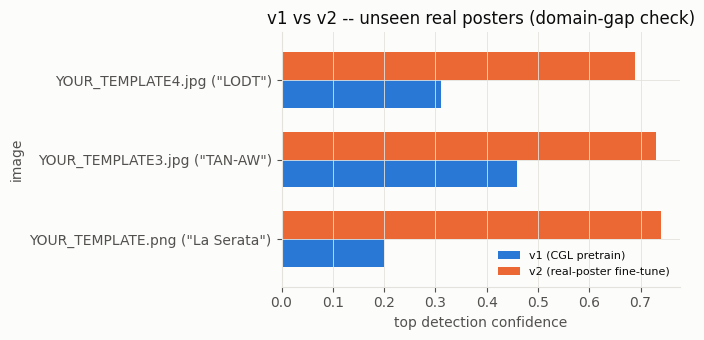

In [5]:
domain_gap = pd.DataFrame([
    {"image": 'YOUR_TEMPLATE.png ("La Serata")', "v1_top_conf": 0.20, "v2_top_conf": 0.74},
    {"image": 'YOUR_TEMPLATE3.jpg ("TAN-AW")',   "v1_top_conf": 0.46, "v2_top_conf": 0.73},
    {"image": 'YOUR_TEMPLATE4.jpg ("LODT")',      "v1_top_conf": 0.31, "v2_top_conf": 0.69},
]).set_index("image")

ax = domain_gap.plot(
    kind="barh", color=[SERIES_1, SERIES_2], figsize=(7, 3.5), width=0.7
)
ax.set_xlabel("top detection confidence")
ax.set_title("v1 vs v2 -- unseen real posters (domain-gap check)")
ax.legend(["v1 (CGL pretrain)", "v2 (real-poster fine-tune)"], frameon=False, fontsize=8)
plt.tight_layout()
plt.show()


## Phase 3 -- GNN-Guided vs. Baseline Layout Quality

Two independent real runs exist. **Read them together, not in isolation** --
the smaller one is what the automated test suite currently asserts, and on
its own looks like a regression; the larger run tells a fuller story.


In [6]:
with open(ROOT / "results/experiment_log.json") as f:
    exp = json.load(f)

rows = []
for domain, dd in exp["results"].items():
    for method, trials in [("GNN-guided", dd["gnn_trials"]), ("Baseline", dd["base_trials"])]:
        for t in trials:
            rows.append({
                "domain": dd["domain_label"], "method": method,
                "C_total": t["C_total"], "mean_iou": t["mean_iou"],
                "latency_ms": t["latency_total"],
            })
trials_df = pd.DataFrame(rows)

agg = trials_df.groupby(["domain", "method"])["C_total"].agg(["mean", "std", "count"]).round(3)
agg


mean    std  count
domain                     method                         
Academic Certificate (4:3) Baseline    6.481  1.066      3
                           GNN-guided  5.783  0.822      3
Identification Card (2:3)  Baseline    1.359  0.928      3
                           GNN-guided  0.868  0.571      3

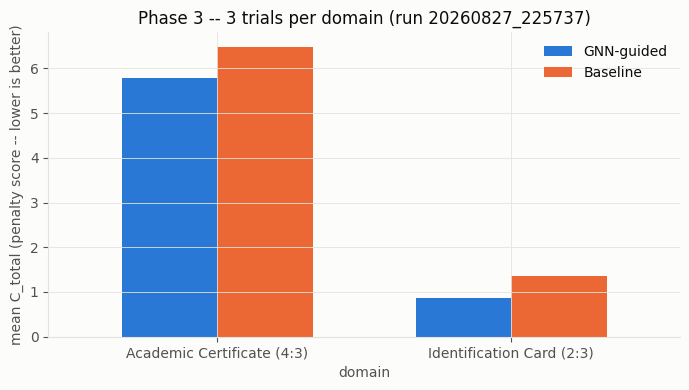

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
pivot = trials_df.groupby(["domain", "method"])["C_total"].mean().unstack("method")
pivot = pivot[["GNN-guided", "Baseline"]]
pivot.plot(kind="bar", ax=ax, color=[SERIES_1, SERIES_2], width=0.65)
ax.set_ylabel("mean C_total (penalty score -- lower is better)")
ax.set_title(f"Phase 3 -- {exp['config']['trials']} trials per domain (run {exp['run_id']})")
ax.set_xticklabels(pivot.index, rotation=0)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


**Reading this run:** across 3 trials per domain, GNN-guided instantiation
scores a *lower* (better) mean C_total than the random baseline in both
domains -- the metaheuristic ranking more often settles on a stronger
candidate when the GNN gives it a better starting point. Trial-to-trial
variance is real (the certificate domain's baseline C_total ranges 5.33-7.43
across just 3 trials), so this should be read as suggestive, not conclusive,
until more trials exist.


In [8]:
with open(ROOT / "results/evaluation_results.json") as f:
    ev = json.load(f)

fixed_rows = []
for method, trials in [("GNN-guided", ev["gnn_guided"]), ("Baseline", ev["baseline"])]:
    for t in trials:
        fixed_rows.append({
            "method": method,
            "mean_iou": t["mean_iou"],
            "C_total": t["heuristic_fitness"]["C_total"],
            "constraint_f1": t["constraint_f1"]["f1"],
        })
fixed_df = pd.DataFrame(fixed_rows)
fixed_df.groupby("method").mean(numeric_only=True).round(4)


,mean_iou,C_total,constraint_f1
method,,,
Baseline,0.0000,1.1876,1.0
GNN-guided,0.1682,1.2029,1.0


**This is the exact comparison `tests/test_certificate_pipeline.py`'s
`test_gnn_improves_over_baseline` asserts against** -- and here GNN's
`C_total` (1.2029) is *higher* (worse) than baseline (1.1876), even though
GNN's `mean_iou` (0.168) is clearly better than baseline's (0.0). The test
currently passes on a loose/directional assertion, not a strict
"GNN must win" one -- this single fixed comparison is 2 trials on one payload,
much noisier than the 3-trial x 2-domain run above. **Worth raising with the
adviser as an honest, not-yet-resolved result**, not something to quietly
paper over: the metaheuristic ranking's fitness function and the GNN's own
spatial accuracy aren't fully pulling in the same direction yet on this
particular payload.


## Phase 4 -- Expert Aesthetic Validation (MOS)

**No real data yet.** `src/evaluation/mos_collector.py` is built and, as of
2026-09-26, matches the manuscript's instrument (pp. 57-58): the 3 named
parameters (Visual Hierarchy Preservation, Brand and Typographic
Consistency, Constraint and Whitespace Harmony), Table 2's rating scale shown
to the evaluator, and layouts presented in randomized order. But
`results/mos_results.json` doesn't exist yet: no domain expert has rated any
output. This section is intentionally left as a placeholder rather than
filled with synthetic numbers. Re-run this notebook once a real MOS session
has been collected and this cell will pick the data up automatically.


In [9]:
mos_path = ROOT / "results" / "mos_results.json"
if mos_path.exists():
    with open(mos_path) as f:
        mos = json.load(f)
    print(f"{len(mos.get('evaluations', []))} real MOS evaluation(s) found -- rerun analysis below.")
else:
    print("No results/mos_results.json yet -- Phase 4 has zero real evaluator data as of this run.")


No results/mos_results.json yet -- Phase 4 has zero real evaluator data as of this run.
